# 3. Convolutional Neural Networks

Suited for:
- Image processing
- Pattern recognition

In [10]:
import keras

In [11]:
# Number of images in each batch
batch_size = 32

# 32x32 pixel images in input data
img_size = (32, 32)

In [12]:
train_data, validation_dataset = keras.utils.image_dataset_from_directory(
    'dataset/train',
    batch_size=batch_size,
    image_size=img_size,
    label_mode='categorical',
    validation_split=0.2,
    subset='both',
    seed=123
)

Found 50000 files belonging to 10 classes.
Using 40000 files for training.
Using 10000 files for validation.


In [13]:
test_data = keras.utils.image_dataset_from_directory(
    'dataset/test',
    batch_size=batch_size,
    image_size=img_size,
    label_mode='categorical'
)

Found 10000 files belonging to 10 classes.


## Model
In the cell below, simple CNN (convolutional neural network) Model is built and compiled.

In [14]:
from keras import Sequential
from keras import layers

In [15]:
model = Sequential([
    layers.Rescaling(scale=1./255),
    layers.Conv2D(32, (3, 3), activation='relu'), 
    layers.MaxPooling2D((2, 2)), 
    layers.Conv2D(64, (3, 3), activation='relu'), 
    layers.MaxPooling2D((2, 2)), 
    layers.Flatten(), 
    layers.Dense(64, activation='relu'), 
    layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Now, train the model for 10 epochs.
(Note that the Keras `fit` method accepts `datasets` for training)

In [16]:

history = model.fit(
    train_data, 
    validation_data=validation_dataset,    
    epochs=10, 
    verbose=1)

Epoch 1/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 78s 59ms/step - accuracy: 0.4511 - loss: 1.5210 - val_accuracy: 0.5389 - val_loss: 1.2998
Epoch 2/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 24s 19ms/step - accuracy: 0.5915 - loss: 1.1659 - val_accuracy: 0.6152 - val_loss: 1.0982
Epoch 3/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 26s 21ms/step - accuracy: 0.6407 - loss: 1.0335 - val_accuracy: 0.6317 - val_loss: 1.0453
Epoch 4/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 26s 20ms/step - accuracy: 0.6698 - loss: 0.9439 - val_accuracy: 0.6434 - val_loss: 1.0346
Epoch 5/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 27s 21ms/step - accuracy: 0.6949 - loss: 0.8780 - val_accuracy: 0.6531 - val_loss: 1.0005
Epoch 6/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 26s 21ms/step - accuracy: 0.7150 - loss: 0.8265 - val_accuracy: 0.6642 - val_loss: 0.9772
Epoch 7/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 26s 21ms/step - accuracy: 0.7321 - loss: 0.7707 - val_accuracy: 0.6696 - val_loss: 0.9978
Epoch 8/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 29s 23ms/step - accuracy: 0.7457 -

In [18]:
import matplotlib.pyplot as plt

In [19]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

In [20]:
epochs = range(1, len(acc)+1)

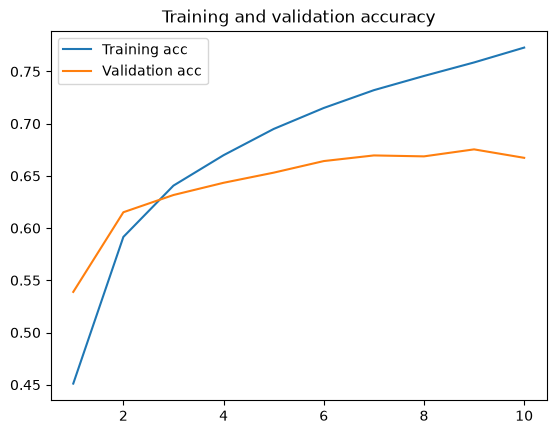

In [21]:
plt.plot(epochs, acc, label='Training acc')
plt.plot(epochs, val_acc, label='Validation acc')
plt.title('Training and validation accuracy')
plt.legend()

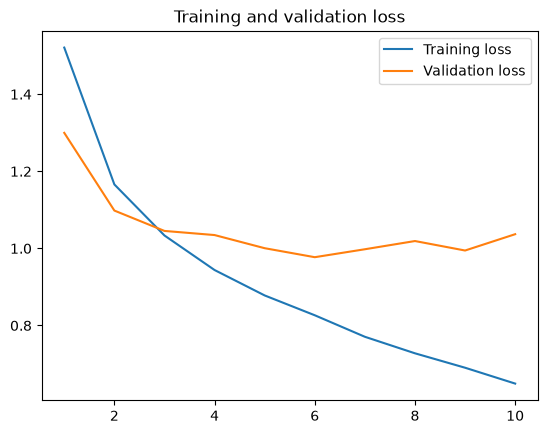

In [22]:
plt.figure()        

plt.plot(epochs, loss, label='Training loss')
plt.plot(epochs, val_loss, label='Validation loss')
plt.title('Training and validation loss')
plt.legend()

plt.show()

Training curves show signs of **overfitting**.

## Convnets and Overfitting

In [23]:
data_augmentation = Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.2),
])

In [25]:
model = Sequential([ 
    layers.Input(shape=(32, 32, 3)),
    data_augmentation,
    layers.Rescaling(scale=1./255),
    layers.Conv2D(32, (3, 3), activation='relu'), 
    layers.MaxPooling2D((2, 2)), 
    layers.Conv2D(64, (3, 3), activation='relu'), 
    layers.MaxPooling2D((2, 2)), 
    layers.Flatten(),
    layers.Dropout(0.2),
    layers.Dense(64, activation='relu'), 
    layers.Dense(10, activation='softmax') ]) 

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

history = model.fit(
    train_data, 
    validation_data=validation_dataset,    
    epochs=20, 
    verbose=1)

Epoch 1/20


c:\Users\araz3\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1250/1250 ━━━━━━━━━━━━━━━━━━━━ 38s 27ms/step - accuracy: 0.3809 - loss: 1.7129 - val_accuracy: 0.4771 - val_loss: 1.4573
Epoch 2/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 35s 28ms/step - accuracy: 0.4710 - loss: 1.4716 - val_accuracy: 0.5274 - val_loss: 1.3417
Epoch 3/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 35s 28ms/step - accuracy: 0.5049 - loss: 1.3876 - val_accuracy: 0.5442 - val_loss: 1.2922
Epoch 4/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 35s 28ms/step - accuracy: 0.5343 - loss: 1.3198 - val_accuracy: 0.5722 - val_loss: 1.2173
Epoch 5/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 35s 28ms/step - accuracy: 0.5415 - loss: 1.2866 - val_accuracy: 0.5655 - val_loss: 1.2392
Epoch 6/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 35s 28ms/step - accuracy: 0.5554 - loss: 1.2479 - val_accuracy: 0.5816 - val_loss: 1.1821
Epoch 7/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 35s 28ms/step - accuracy: 0.5660 - loss: 1.2273 - val_accuracy: 0.5902 - val_loss: 1.1785
Epoch 8/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 35s 28ms/step - accuracy: 0.5730 - loss: 1.20

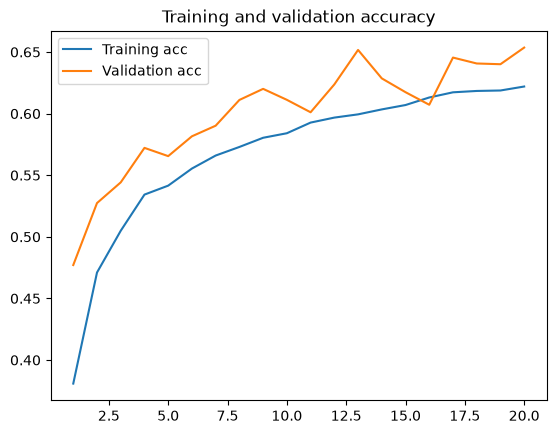

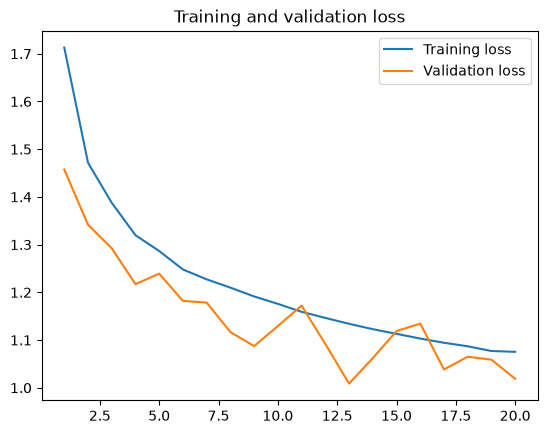

In [26]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(1, len(acc)+1)

plt.plot(epochs, acc, label='Training acc')
plt.plot(epochs, val_acc, label='Validation acc')
plt.title('Training and validation accuracy')
plt.legend()

plt.figure()        

plt.plot(epochs, loss, label='Training loss')
plt.plot(epochs, val_loss, label='Validation loss')
plt.title('Training and validation loss')
plt.legend()

plt.show()

In [27]:
test_loss, test_acc = model.evaluate(test_data)
print(f'Test accuracy: {test_acc:.4f}')

313/313 ━━━━━━━━━━━━━━━━━━━━ 12s 37ms/step - accuracy: 0.6507 - loss: 1.0056
Test accuracy: 0.6507
